# EDA - IBM AML / HI-Small_Trans

Khám phá dữ liệu giao dịch tài chính và chuẩn bị cho bài toán GraphX/GraphFrames.
Nguồn: [IBM Transactions for Anti Money Laundering (AML)](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml).
Phạm vi: toàn bộ file `HI-Small_Trans.csv`, không phải toàn bộ các phiên bản của dataset.
Dữ liệu là giao dịch tổng hợp; `Is Laundering = 1` là nhãn rửa tiền do bộ dữ liệu cung cấp.
Các kết quả sẽ được tính khi chạy, không suy diễn nhãn từ số tiền hoặc cấu trúc mạng.

**Câu hỏi EDA:** dữ liệu có vấn đề chất lượng nào, nhãn mất cân bằng đến mức nào, các nhóm giao dịch khác nhau ra sao, và mạng tài khoản có đặc điểm gì?
Chạy lần lượt tất cả các ô bằng kernel đã cài `requirements-eda.txt`.

In [1]:
from pathlib import Path
import gc
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/download_aml.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục graphX hoặc notebooks/.')
DATA_PATH = ROOT / 'data/raw/HI-Small_Trans.csv'
REPORT_DIR = ROOT / 'reports'
REPORT_DIR.mkdir(exist_ok=True)
SEED = 42
PLOT_SAMPLE = 200_000
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.grid': True, 'grid.alpha': 0.2, 'figure.dpi': 110})

def save_figure(name):
    plt.tight_layout()
    plt.savefig(REPORT_DIR / f'{name}.png', bbox_inches='tight', dpi=140)
    plt.show()
    plt.close()

def export_table(table, name):
    table.to_csv(REPORT_DIR / f'{name}.csv', index=True)
    display(table)

versions = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__, 'matplotlib': matplotlib.__version__}
print('Phiên bản:', versions)
print('File:', DATA_PATH)

Phiên bản: {'python': '3.13.11', 'pandas': '3.0.6', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}
File: /home/tuanta/graphX/data/raw/HI-Small_Trans.csv


## 1. Đọc dữ liệu và mô tả schema

Nếu file chưa tồn tại, chạy `python scripts/download_aml.py` tại thư mục gốc.
CSV có hai cột cùng tên `Account`; pandas đọc cột thứ hai thành `Account.1`.
Ta đổi tên rõ ràng thành tài khoản gửi và nhận, giữ mã ngân hàng/tài khoản ở dạng chuỗi để bảo toàn số 0 đầu.
Các cột định danh dùng `category` để giảm RAM; số tiền giữ `float64`.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError('Chạy python scripts/download_aml.py trước khi chạy EDA.')
raw_columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
expected = ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']
assert raw_columns == expected, f'Schema thay đổi: {raw_columns}'
dtypes = {c: 'category' for c in ['From Bank', 'Account', 'To Bank', 'Account.1', 'Receiving Currency', 'Payment Currency', 'Payment Format']}
dtypes.update({'Amount Received': 'float64', 'Amount Paid': 'float64', 'Is Laundering': 'float64'})
df = pd.read_csv(DATA_PATH, dtype=dtypes).rename(columns={
    'Timestamp': 'timestamp', 'From Bank': 'from_bank', 'Account': 'from_account',
    'To Bank': 'to_bank', 'Account.1': 'to_account', 'Amount Received': 'amount_received',
    'Receiving Currency': 'receiving_currency', 'Amount Paid': 'amount_paid',
    'Payment Currency': 'payment_currency', 'Payment Format': 'payment_format', 'Is Laundering': 'is_laundering',
})
raw_timestamp_missing = int(df['timestamp'].isna().sum())
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y/%m/%d %H:%M', errors='coerce')
assert df['is_laundering'].notna().all() and df['is_laundering'].isin([0, 1]).all(), 'Nhãn thiếu hoặc khác 0/1: cần xử lý trước khi phân tích.'
df['is_laundering'] = df['is_laundering'].astype('uint8')
N = len(df)
print(f'{N:,} giao dịch; {df.shape[1]} cột; RAM DataFrame: {df.memory_usage(deep=True).sum()/1024**2:,.1f} MiB')
display(df.head())
schema = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'unique': df.nunique(dropna=True)})
export_table(schema, 'schema')

5,078,345 giao dịch; 11 cột; RAM DataFrame: 280.7 MiB


,timestamp,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering
0,2022-09-01 00:20:00,010,8000EBD30,010,8000EBD30,"3,697.3400",US Dollar,"3,697.3400",US Dollar,Reinvestment,0
1,2022-09-01 00:20:00,03208,8000F4580,001,8000F5340,0.0100,US Dollar,0.0100,US Dollar,Cheque,0
2,2022-09-01 00:00:00,03209,8000F4670,03209,8000F4670,"14,675.5700",US Dollar,"14,675.5700",US Dollar,Reinvestment,0
3,2022-09-01 00:02:00,012,8000F5030,012,8000F5030,"2,806.9700",US Dollar,"2,806.9700",US Dollar,Reinvestment,0
4,2022-09-01 00:06:00,010,8000F5200,010,8000F5200,"36,682.9700",US Dollar,"36,682.9700",US Dollar,Reinvestment,0


,dtype,missing,unique
timestamp,datetime64[us],0,15018
from_bank,category,0,30528
from_account,category,0,496995
to_bank,category,0,15850
to_account,category,0,420636
amount_received,float64,0,915161
receiving_currency,category,0,15
amount_paid,float64,0,923873
payment_currency,category,0,15
payment_format,category,0,7


In [3]:
dictionary = pd.DataFrame([
    ('timestamp', 'Thời điểm giao dịch; nguồn không chỉ rõ múi giờ'),
    ('from_bank / to_bank', 'Mã ngân hàng gửi / nhận, giữ số 0 đầu'),
    ('from_account / to_account', 'Mã tài khoản gửi / nhận, không phải đặc trưng số'),
    ('amount_paid / amount_received', 'Số tiền theo payment_currency / receiving_currency tương ứng'),
    ('payment_currency / receiving_currency', 'Tiền tệ ở hai đầu giao dịch'),
    ('payment_format', 'Phương thức thanh toán'),
    ('is_laundering', 'Nhãn nhị phân 0/1 của giao dịch, không phải nhãn tài khoản'),
], columns=['column', 'meaning'])
display(dictionary)

,column,meaning
0,timestamp,Thời điểm giao dịch; nguồn không chỉ rõ múi giờ
1,from_bank / to_bank,"Mã ngân hàng gửi / nhận, giữ số 0 đầu"
2,from_account / to_account,"Mã tài khoản gửi / nhận, không phải đặc trưng số"
3,amount_paid / amount_received,Số tiền theo payment_currency / receiving_curr...
4,payment_currency / receiving_currency,Tiền tệ ở hai đầu giao dịch
5,payment_format,Phương thức thanh toán
6,is_laundering,"Nhãn nhị phân 0/1 của giao dịch, không phải nh..."


## 2. Chất lượng dữ liệu

Kiểm tra toàn bộ dữ liệu trước khi tạo đặc trưng.
Dòng trùng hoàn toàn chưa chắc là lỗi vì nguồn không có transaction ID; giữ nguyên và báo cáo số lượng.
Self-loop hoặc số tiền bằng 0 cũng cần xem xét theo ngữ cảnh, không tự động loại bỏ.

In [4]:
missing = df.isna().sum().to_frame('missing_count')
missing['missing_pct'] = missing['missing_count'] / N * 100
export_table(missing, 'missing_values')
amounts = ['amount_paid', 'amount_received']
quality = {
    'rows': N,
    'exact_duplicate_rows_after_first': int(df.duplicated().sum()),
    'missing_raw_timestamps': raw_timestamp_missing,
    'invalid_nonmissing_timestamps': int(df.timestamp.isna().sum()) - raw_timestamp_missing,
}
for c in amounts:
    quality[f'{c}_negative'] = int(df[c].lt(0).sum())
    quality[f'{c}_zero'] = int(df[c].eq(0).sum())
    quality[f'{c}_nonfinite'] = int((~np.isfinite(df[c])).sum())
export_table(pd.Series(quality, name='value').to_frame(), 'quality_checks')
identifier_columns = ['from_bank', 'from_account', 'to_bank', 'to_account']
assert not df[identifier_columns].isna().any().any(), 'Có định danh thiếu, cần xử lý trước khi dựng graph.'
assert quality['invalid_nonmissing_timestamps'] == 0 and raw_timestamp_missing == 0, 'Timestamp lỗi cần xử lý trước EDA thời gian.'
assert all(quality[f'{c}_nonfinite'] == 0 and quality[f'{c}_negative'] == 0 for c in amounts), 'Số tiền bất thường cần xử lý trước biểu đồ.'

,missing_count,missing_pct
timestamp,0,0.0000
from_bank,0,0.0000
from_account,0,0.0000
to_bank,0,0.0000
to_account,0,0.0000
amount_received,0,0.0000
receiving_currency,0,0.0000
amount_paid,0,0.0000
payment_currency,0,0.0000
payment_format,0,0.0000


,value
rows,5078345
exact_duplicate_rows_after_first,9
missing_raw_timestamps,0
invalid_nonmissing_timestamps,0
amount_paid_negative,0
amount_paid_zero,0
amount_paid_nonfinite,0
amount_received_negative,0
amount_received_zero,0
amount_received_nonfinite,0


## 3. Phân bố nhãn và thời gian

Tỷ lệ rửa tiền được tính trên toàn bộ giao dịch.
Một mô hình luôn dự đoán 0 có thể đạt accuracy cao khi nhãn hiếm; khi mô hình hóa nên xem precision, recall và PR-AUC.
Chuỗi thời gian dưới đây giữ nguyên thứ tự ngày và không giả định CSV đã được sắp xếp theo timestamp.

,transactions,pct
is_laundering,,
0,5073168,99.8981
1,5177,0.1019


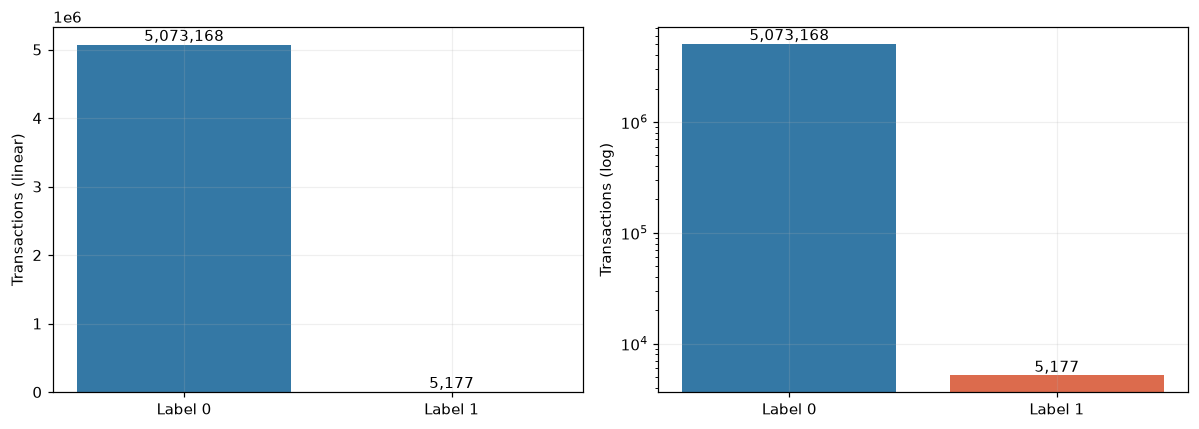

In [5]:
labels = df.groupby('is_laundering', observed=True).size().reindex([0, 1], fill_value=0).to_frame('transactions')
labels['pct'] = labels.transactions / N * 100
export_table(labels, 'label_distribution')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, scale in zip(axes, ['linear', 'log']):
    ax.bar(['Label 0', 'Label 1'], labels.transactions, color=['#3478a5', '#dc6b4d'])
    ax.set_yscale(scale)
    ax.set_ylabel(f'Transactions ({scale})')
    for i, value in enumerate(labels.transactions): ax.text(i, value, f'{value:,}', ha='center', va='bottom')
save_figure('labels')

,transactions,laundering,laundering_rate_pct
2022-09-01,1114921,322,0.0289
2022-09-02,754449,408,0.0541
2022-09-03,207382,391,0.1885
2022-09-04,207430,407,0.1962
2022-09-05,482650,471,0.0976
2022-09-06,482089,531,0.1101
2022-09-07,482751,497,0.1030
2022-09-08,482773,539,0.1116
2022-09-09,654467,514,0.0785
2022-09-10,208325,442,0.2122


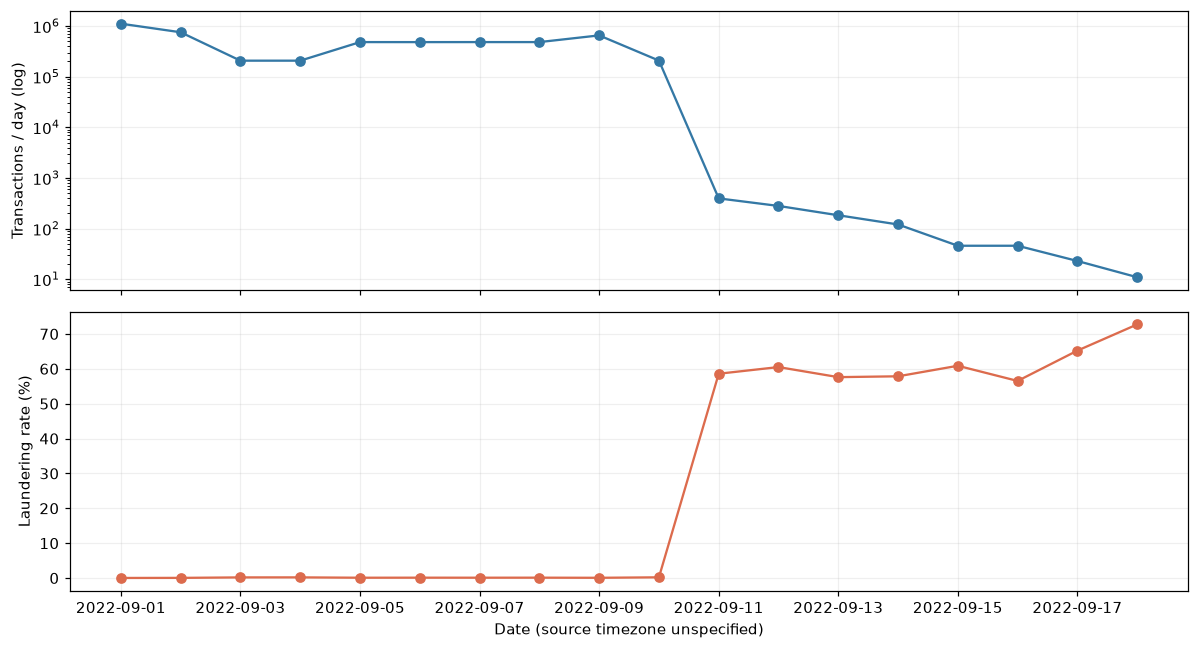

Khoảng thời gian: 2022-09-01 00:00:00 -> 2022-09-18 16:18:00
CSV đã sắp theo thời gian: False


Từ **2022-09-11**, chỉ còn **1,108 giao dịch**, trong đó **655 nhãn 1 (59.12%)**. Lượng giao dịch giảm mạnh và tỷ lệ nhãn đổi rõ rệt; cần kiểm tra tính đại diện của từng giai đoạn khi chia train/test theo thời gian. Tỷ lệ cao ở các ngày cuối có mẫu số rất nhỏ và không chứng minh một xu hướng ngoài dữ liệu tổng hợp.

In [6]:
daily = df.groupby(df.timestamp.dt.floor('D'), observed=True)['is_laundering'].agg(transactions='size', laundering='sum')
daily = daily.reindex(pd.date_range(df.timestamp.min().normalize(), df.timestamp.max().normalize(), freq='D'), fill_value=0)
daily['laundering_rate_pct'] = daily.laundering.div(daily.transactions.replace(0, np.nan)) * 100
export_table(daily, 'daily_activity')
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(daily.index, daily.transactions, marker='o', color='#3478a5')
axes[0].set_yscale('log')
axes[0].set_ylabel('Transactions / day (log)')
axes[1].plot(daily.index, daily.laundering_rate_pct, marker='o', color='#dc6b4d')
axes[1].set_ylabel('Laundering rate (%)')
axes[1].set_xlabel('Date (source timezone unspecified)')
save_figure('daily_activity')
print('Khoảng thời gian:', df.timestamp.min(), '->', df.timestamp.max())
print('CSV đã sắp theo thời gian:', df.timestamp.is_monotonic_increasing)
# Điểm đổi chế độ quan sát được trong bảng daily, không phải ngưỡng học từ nhãn.
late = daily.loc['2022-09-11':]
late_count = int(late.transactions.sum())
late_positive = int(late.laundering.sum())
display(Markdown(f'Từ **2022-09-11**, chỉ còn **{late_count:,} giao dịch**, trong đó **{late_positive:,} nhãn 1 ({late_positive/late_count*100:.2f}%)**. '
                 'Lượng giao dịch giảm mạnh và tỷ lệ nhãn đổi rõ rệt; cần kiểm tra tính đại diện của từng giai đoạn khi chia train/test theo thời gian. '
                 'Tỷ lệ cao ở các ngày cuối có mẫu số rất nhỏ và không chứng minh một xu hướng ngoài dữ liệu tổng hợp.'))

,transactions,laundering,laundering_rate_pct
timestamp,,,
0,634726,176,0.0277
1,193728,152,0.0785
2,193143,165,0.0854
3,193249,146,0.0756
4,193166,154,0.0797
5,193900,188,0.0970
6,194456,207,0.1065
7,193336,195,0.1009
8,192921,258,0.1337


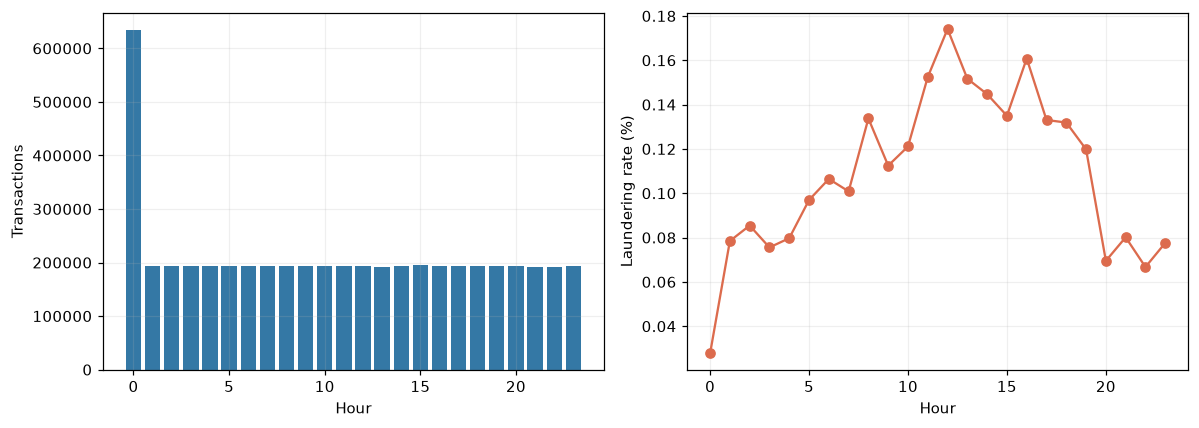

In [7]:
hourly = df.groupby(df.timestamp.dt.hour, observed=True)['is_laundering'].agg(transactions='size', laundering='sum').reindex(range(24), fill_value=0)
hourly['laundering_rate_pct'] = hourly.laundering.div(hourly.transactions.replace(0, np.nan)) * 100
export_table(hourly, 'hourly_activity')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(hourly.index, hourly.transactions, color='#3478a5')
axes[0].set(xlabel='Hour', ylabel='Transactions')
axes[1].plot(hourly.index, hourly.laundering_rate_pct, marker='o', color='#dc6b4d')
axes[1].set(xlabel='Hour', ylabel='Laundering rate (%)')
save_figure('hourly_activity')

## 4. Phương thức thanh toán và tiền tệ

Mỗi nhóm có cả số lượng giao dịch và tỷ lệ nhãn 1 để phân biệt quy mô với mức tập trung của nhãn.
Wilson 95% CI mô tả độ bất định của tỷ lệ theo mô hình nhị thức; giao dịch có thể phụ thuộc lẫn nhau nên đây chỉ là tham khảo mô tả.
Không diễn giải chênh lệch nhóm như quan hệ nhân quả hoặc bằng chứng rửa tiền của một tài khoản.

,transactions,laundering,share_pct,laundering_rate_pct,ci_low_pct,ci_high_pct
payment_format,,,,,,
Cheque,1864331,324,36.7114,0.0174,0.0156,0.0194
Credit Card,1323324,206,26.0582,0.0156,0.0136,0.0178
ACH,600797,4483,11.8306,0.7462,0.7247,0.7683
Cash,490891,108,9.6664,0.0220,0.0182,0.0266
Reinvestment,481056,0,9.4727,0.0000,0.0000,0.0008
Wire,171855,0,3.3841,0.0000,0.0000,0.0022
Bitcoin,146091,56,2.8767,0.0383,0.0295,0.0498


,transactions,laundering,share_pct,laundering_rate_pct,ci_low_pct,ci_high_pct
payment_currency,,,,,,
US Dollar,1895172,1912,37.3187,0.1009,0.0965,0.1055
Euro,1168297,1372,23.0055,0.1174,0.1114,0.1238
Swiss Franc,234860,193,4.6247,0.0822,0.0714,0.0946
Yuan,213752,184,4.2091,0.0861,0.0745,0.0994
Shekel,192184,95,3.7844,0.0494,0.0404,0.0604
Rupee,190202,167,3.7454,0.0878,0.0755,0.1022
UK Pound,180738,132,3.5590,0.0730,0.0616,0.0866
Yen,155209,155,3.0563,0.0999,0.0853,0.1169
Ruble,155178,133,3.0557,0.0857,0.0723,0.1016


,transactions,laundering,share_pct,laundering_rate_pct,ci_low_pct,ci_high_pct
receiving_currency,,,,,,
US Dollar,1879341,1912,37.0070,0.1017,0.0973,0.1064
Euro,1172017,1372,23.0787,0.1171,0.1110,0.1234
Swiss Franc,237884,193,4.6843,0.0811,0.0705,0.0934
Yuan,206551,184,4.0673,0.0891,0.0771,0.1029
Shekel,194988,95,3.8396,0.0487,0.0399,0.0595
Rupee,192065,167,3.7820,0.0869,0.0747,0.1012
UK Pound,181255,132,3.5692,0.0728,0.0614,0.0863
Ruble,157361,133,3.0987,0.0845,0.0713,0.1001
Yen,156319,155,3.0781,0.0992,0.0847,0.1160


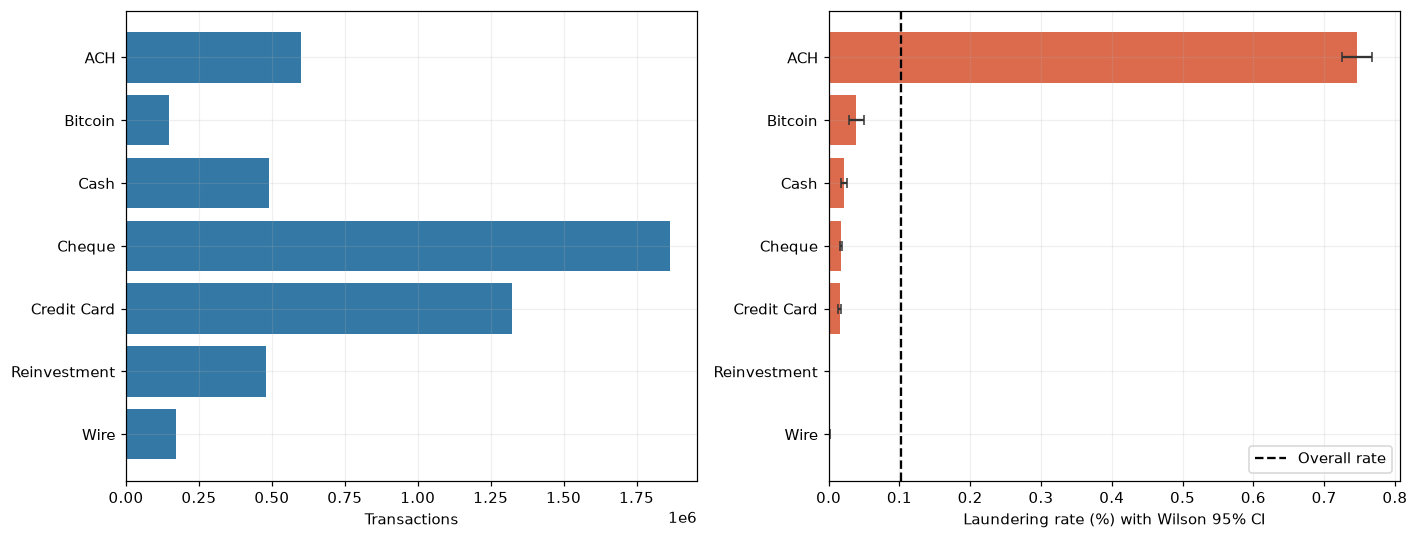

In [8]:
def label_profile(column):
    result = df.groupby(column, observed=True)['is_laundering'].agg(transactions='size', laundering='sum')
    result['share_pct'] = result.transactions / N * 100
    p = result.laundering / result.transactions
    z = 1.96
    denominator = 1 + z*z/result.transactions
    center = (p + z*z/(2*result.transactions)) / denominator
    half = z * np.sqrt(p*(1-p)/result.transactions + z*z/(4*result.transactions**2)) / denominator
    result['laundering_rate_pct'] = p * 100
    result['ci_low_pct'] = (center-half).clip(lower=0) * 100
    result['ci_high_pct'] = (center+half).clip(upper=1) * 100
    return result.sort_values('transactions', ascending=False)

profiles = {}
for column in ['payment_format', 'payment_currency', 'receiving_currency']:
    profiles[column] = label_profile(column)
    export_table(profiles[column], column + '_profile')
profile = profiles['payment_format'].sort_values('laundering_rate_pct')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(profile.index.astype(str), profile.transactions, color='#3478a5')
axes[0].set_xlabel('Transactions')
axes[1].barh(profile.index.astype(str), profile.laundering_rate_pct, color='#dc6b4d')
axes[1].errorbar(profile.laundering_rate_pct, np.arange(len(profile)), xerr=[profile.laundering_rate_pct-profile.ci_low_pct, profile.ci_high_pct-profile.laundering_rate_pct], fmt='none', ecolor='#333333', capsize=3)
axes[1].axvline(df.is_laundering.mean()*100, linestyle='--', color='black', label='Overall rate')
axes[1].set_xlabel('Laundering rate (%) with Wilson 95% CI')
axes[1].legend()
save_figure('payment_format')

## 5. Số tiền và tương quan

Không cộng hoặc so sánh trực tiếp số tiền của các tiền tệ khác nhau vì chưa có tỷ giá.
Thống kê và biểu đồ dưới đây tách theo `payment_currency`.
Hai loại tiền bằng nhau được dùng khi so sánh `amount_paid` và `amount_received`.
Khác biệt ở hai đầu không tự động là gian lận; nguồn không cung cấp phí hoặc tỷ giá.

count             mean  \
payment_currency  is_laundering                                   
Australian Dollar 0               136,642.0000     341,942.7670   
                  1                   127.0000   1,414,562.5361   
Bitcoin           0               146,010.0000          20.8170   
                  1                    56.0000           0.6254   
Canadian Dollar   0               139,914.0000     415,490.1750   
                  1                   128.0000 178,334,138.7269   
Euro              0             1,166,925.0000     262,356.1085   
                  1                 1,372.0000     925,156.4425   
Mexican Peso      0               110,067.0000   5,961,755.0424   
                  1                    92.0000   2,691,192.5654   
Ruble             0               155,045.0000  42,674,617.4416   
                  1                   133.0000 638,684,409.6839   
Rupee             0               190,035.0000  36,514,833.9353   
                  1                   167.0000 412,782,957.7150   
UK Pound          0               180,606.0000     251,360.7177   
                  1                   132.0000   3,698,951.4645   
US Dollar         0             1,893,260.0000     366,886.3122   
                  1                 1,912.0000     632,000.6155   
Yen               0               155,054.0000  41,056,908.8536   
                  1                   155.0000   3,379,896.4402   
Yuan              0               213,568.0000   1,643,231.9229   
                  1                   184.0000   2,283,537.0599   
Brazil Real       0                70,646.0000   4,387,243.3671   
                  1                    57.0000      42,238.2289   
Saudi Riyal       0                88,640.0000     684,632.0863   
                  1                   374.0000   8,139,970.1135   
Shekel            0               192,089.0000     984,756.0157   
                  1                    95.0000   2,305,522.9606   
Swiss Franc       0               234,667.0000     311,133.8438   
                  1                   193.0000  14,315,623.6849   

                                               std        min          50%  \
payment_currency  is_laundering                                              
Australian Dollar 0                11,882,895.7385     0.0100   1,298.9800   
                  1                13,837,205.4353   113.6200   5,680.7800   
Bitcoin           0                       688.0223     0.0000       0.0698   
                  1                         1.9360     0.0032       0.2479   
Canadian Dollar   0                18,962,421.7527     0.0100   1,141.3600   
                  1             1,902,651,709.5094    29.5500   7,498.7250   
Euro              0                16,902,534.1063     0.0100     744.5000   
                  1                13,437,656.9299     0.3300   5,154.4950   
Mexican Peso      0               208,222,703.2136     0.0100  18,853.2300   
                  1                24,140,175.5102   681.4800 127,554.8450   
Ruble             0             2,657,817,010.9338     0.0100  69,851.7900   
                  1             7,357,640,504.0852   813.7900 355,525.6700   
Rupee             0             2,822,676,698.0652     0.0100  65,328.0000   
                  1             5,139,140,403.6692   152.5800 640,426.2300   
UK Pound          0                 7,784,332.9026     0.0100     690.6600   
                  1                33,574,738.6987     7.8000   3,381.8350   
US Dollar         0                21,258,678.2838     0.0100     901.4800   
                  1                 8,283,721.0243     2.2800   5,970.0850   
Yen               0             2,770,664,916.6015     0.0100  95,794.7300   
                  1                21,275,945.1613 3,114.0900 633,401.4300   
Yuan              0                33,893,237.6465     0.0100   6,053.1600   
                  1                20,377,779.4914   229.8200  36,582.2250   
Brazil Real       0     

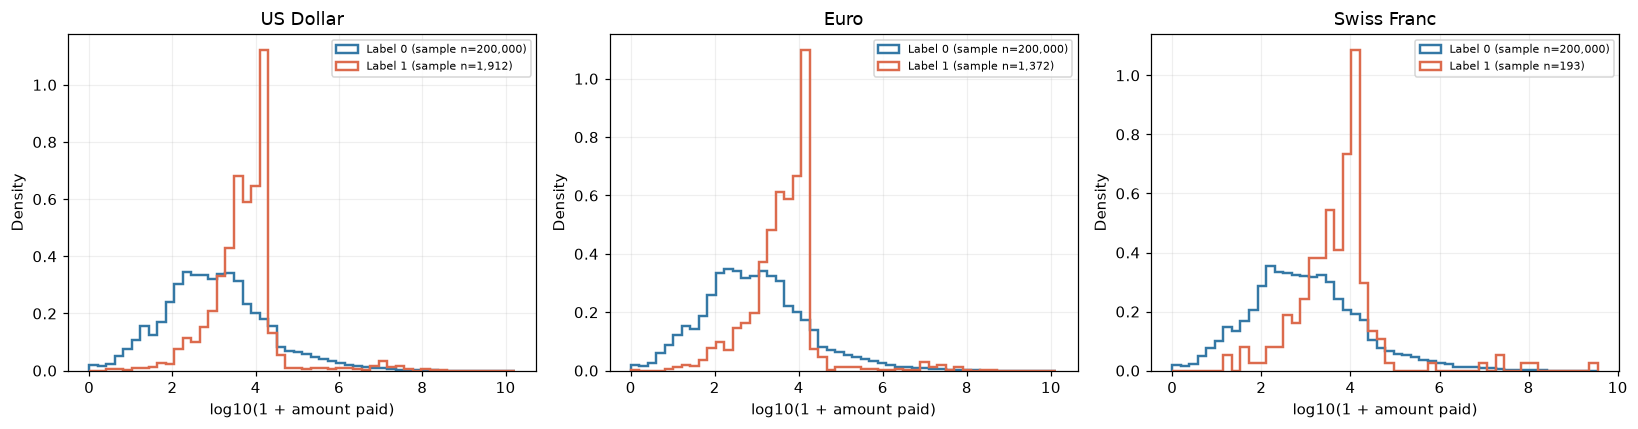

31564

In [9]:
amount_summary = df.groupby(['payment_currency', 'is_laundering'], observed=True).amount_paid.describe(percentiles=[.5, .9, .99])
export_table(amount_summary, 'amount_by_currency_label')
top_currencies = profiles['payment_currency'].head(3).index.tolist()
fig, axes = plt.subplots(1, len(top_currencies), figsize=(15, 4), squeeze=False)
for ax, currency in zip(axes.ravel(), top_currencies):
    subset = df.loc[df.payment_currency == currency, ['amount_paid', 'is_laundering']]
    bins = np.linspace(np.log10(1 + subset.amount_paid.min()), np.log10(1 + subset.amount_paid.max()), 51)
    for label, color in [(0, '#3478a5'), (1, '#dc6b4d')]:
        values = subset.loc[subset.is_laundering == label, 'amount_paid']
        if len(values):
            sample = values.sample(min(PLOT_SAMPLE, len(values)), random_state=SEED)
            ax.hist(np.log10(1 + sample), bins=bins, density=True, histtype='step', linewidth=1.6, color=color, label=f'Label {label} (sample n={len(sample):,})')
    ax.set(title=str(currency), xlabel='log10(1 + amount paid)', ylabel='Density')
    ax.legend(fontsize=7)
save_figure('amount_distribution')
del subset, values, sample
gc.collect()

In [10]:
same_currency = df.payment_currency.astype('string') == df.receiving_currency.astype('string')
comparison = pd.DataFrame({
    'same_currency': same_currency,
    'different_amount_same_currency': same_currency & ~np.isclose(df.amount_paid, df.amount_received, rtol=1e-9, atol=0.005),
    'is_laundering': df.is_laundering,
})
export_table(comparison.groupby('same_currency').is_laundering.agg(transactions='size', laundering='sum'), 'currency_conversion')
print('Giao dịch cùng tiền tệ nhưng khác số tiền (dung sai 0.005):', int(comparison.different_amount_same_currency.sum()))
correlations = []
for currency in top_currencies:
    subset = df.loc[same_currency & (df.payment_currency == currency), ['amount_paid', 'amount_received', 'is_laundering']].copy()
    subset[['amount_paid', 'amount_received']] = np.log1p(subset[['amount_paid', 'amount_received']])
    corr = subset.corr(method='spearman')
    correlations.append((currency, len(subset), corr.loc['amount_paid', 'amount_received'], corr.loc['amount_paid', 'is_laundering']))
export_table(pd.DataFrame(correlations, columns=['currency', 'n', 'spearman_paid_received', 'spearman_paid_label']).set_index('currency'), 'correlations')
del subset, comparison
gc.collect()

,transactions,laundering
same_currency,,
False,72170,0
True,5006175,5177


Giao dịch cùng tiền tệ nhưng khác số tiền (dung sai 0.005): 0


,n,spearman_paid_received,spearman_paid_label
currency,,,
US Dollar,1856392,1.0000,0.0235
Euro,1153708,1.0000,0.0246
Swiss Franc,234429,1.0000,0.0206


0

## 6. EDA mạng giao dịch có hướng

Mỗi tài khoản có khóa `bank:account` để tránh gộp tài khoản thuộc ngân hàng khác nhau.
Mỗi giao dịch là một cạnh có hướng; giữ self-loop và cạnh song song ở bản gốc.
Bậc theo số giao dịch đếm cả cạnh lặp; bậc theo số láng giềng đếm mỗi cặp gửi-nhận một lần.
Self-loop đóng góp 1 vào in-degree và 1 vào out-degree.
Một node có nhiều giao dịch hoặc có tham gia giao dịch nhãn 1 không đồng nghĩa tài khoản đó đã được chứng minh phạm tội.

In [11]:
# Chuyển chuỗi bank:account về category ngay để tiết kiệm RAM.
for bank, account, endpoint in [('from_bank', 'from_account', 'src'), ('to_bank', 'to_account', 'dst')]:
    df[endpoint] = (df[bank].astype('string') + ':' + df[account].astype('string')).astype('category')
self_loop = df.src.astype('string') == df.dst.astype('string')
same_bank = df.from_bank.astype('string') == df.to_bank.astype('string')
flags = pd.DataFrame({'self_loop': self_loop, 'same_bank': same_bank, 'is_laundering': df.is_laundering})
for flag in ['self_loop', 'same_bank']:
    table = flags.groupby(flag).is_laundering.agg(transactions='size', laundering='sum')
    table['laundering_rate_pct'] = table.laundering / table.transactions * 100
    export_table(table, flag + '_profile')

out_degree = df.groupby('src', observed=True).size().rename('out_transactions')
in_degree = df.groupby('dst', observed=True).size().rename('in_transactions')
degrees = pd.concat([out_degree, in_degree], axis=1).fillna(0).astype('int64')
degrees.index.name = 'account_id'
degrees['total_transactions'] = degrees.out_transactions + degrees.in_transactions
assert degrees.out_transactions.sum() == N and degrees.in_transactions.sum() == N

# Các cặp src-dst khác nhau: không nhân Cartesian product của category.
pairs = df.groupby(['src', 'dst'], observed=True, sort=False).size().rename('transactions').reset_index()
neighbors = pd.concat([
    pairs.groupby('src', observed=True).size().rename('out_neighbors'),
    pairs.groupby('dst', observed=True).size().rename('in_neighbors'),
], axis=1).fillna(0).astype('int64')
degrees = degrees.join(neighbors).fillna(0)
degrees[['out_neighbors', 'in_neighbors']] = degrees[['out_neighbors', 'in_neighbors']].astype('int64')
degrees['total_neighbors_directional'] = degrees.out_neighbors + degrees.in_neighbors
# Total này đếm một láng giềng hai lần nếu có cạnh ở cả hai hướng.
graph_summary = {
    'vertices_bank_account': len(degrees), 'transaction_edges': N,
    'unique_directed_pairs_including_loops': len(pairs),
    'self_loop_transactions': int(self_loop.sum()),
    'same_bank_transactions': int(same_bank.sum()),
    'pairs_with_multiple_transactions': int(pairs.transactions.gt(1).sum()),
    'additional_transactions_on_existing_pairs': N - len(pairs),
    'sender_only_vertices': int(degrees.in_transactions.eq(0).sum()),
    'receiver_only_vertices': int(degrees.out_transactions.eq(0).sum()),
}
export_table(pd.Series(graph_summary, name='value').to_frame(), 'graph_summary')
export_table(degrees.nlargest(20, 'total_transactions'), 'top_accounts')
degrees.to_csv(REPORT_DIR / 'account_degrees.csv')
del flags, neighbors, out_degree, in_degree
gc.collect()

,transactions,laundering,laundering_rate_pct
self_loop,,,
False,4487133,5166,0.1151
True,591212,11,0.0019


,transactions,laundering,laundering_rate_pct
same_bank,,,
False,4387090,5074,0.1157
True,691255,103,0.0149


,value
vertices_bank_account,515088
transaction_edges,5078345
unique_directed_pairs_including_loops,1015736
self_loop_transactions,591212
same_bank_transactions,691255
pairs_with_multiple_transactions,561575
additional_transactions_on_existing_pairs,4062609
sender_only_vertices,94448
receiver_only_vertices,18089


,out_transactions,in_transactions,total_transactions,out_neighbors,in_neighbors,total_neighbors_directional
account_id,,,,,,
070:100428660,168672,1084,169756,14230,545,14775
070:1004286A8,103018,653,103671,8846,328,9174
070:100428978,20497,150,20647,1776,75,1851
070:1004286F0,18663,108,18771,1575,55,1630
070:100428780,17264,117,17381,1421,61,1482
070:1004289C0,16794,132,16926,1432,68,1500
070:100428810,16426,114,16540,1394,58,1452
070:1004287C8,14174,103,14277,1182,55,1237
070:100428738,13756,98,13854,1136,51,1187


0

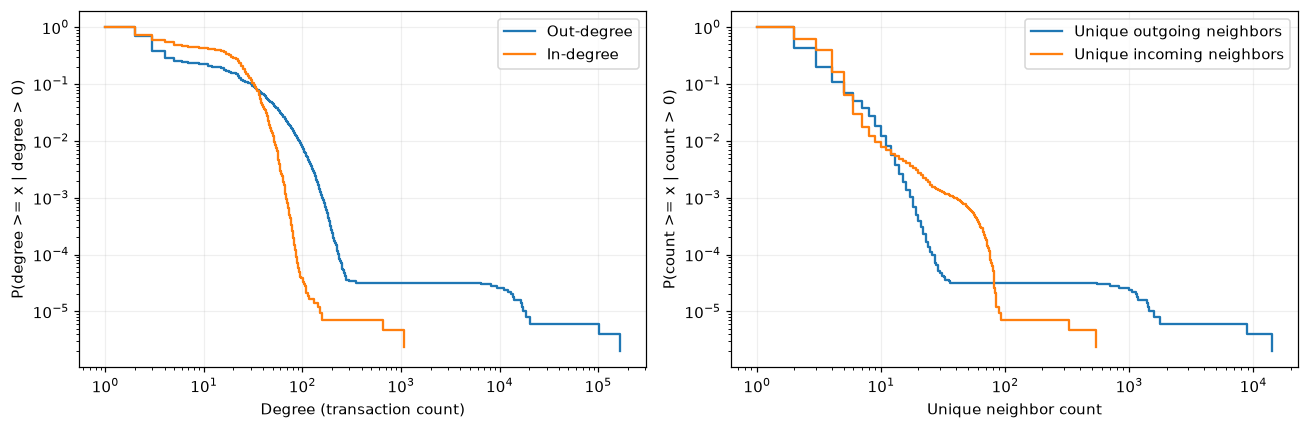

,,transactions
src,dst,
014:80006FCE0,014:80006FCE0,89
0113:8000D09B0,0113:8000D09B0,69
003:800069AA0,003:800069AA0,66
001:800057020,001:800057020,65
020:8007E86B0,020:8007E86B0,65
0220:813424001,0220:813424001,63
001:80005B9B0,001:80005B9B0,62
020:80006AC70,020:80006AC70,62
00513:8003231B0,00513:8003231B0,61


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, label in [('out_transactions', 'Out-degree'), ('in_transactions', 'In-degree')]:
    values = degrees[column].to_numpy()
    counts = pd.Series(values[values > 0]).value_counts().sort_index()
    survival = counts.iloc[::-1].cumsum().iloc[::-1] / counts.sum()
    axes[0].step(survival.index, survival.values, where='post', label=label)
axes[0].set(xscale='log', yscale='log', xlabel='Degree (transaction count)', ylabel='P(degree >= x | degree > 0)')
axes[0].legend()
for column, label in [('out_neighbors', 'Unique outgoing neighbors'), ('in_neighbors', 'Unique incoming neighbors')]:
    values = degrees[column].to_numpy()
    counts = pd.Series(values[values > 0]).value_counts().sort_index()
    survival = counts.iloc[::-1].cumsum().iloc[::-1] / counts.sum()
    axes[1].step(survival.index, survival.values, where='post', label=label)
axes[1].set(xscale='log', yscale='log', xlabel='Unique neighbor count', ylabel='P(count >= x | count > 0)')
axes[1].legend()
save_figure('degree_distributions')
export_table(pairs.nlargest(20, 'transactions').set_index(['src', 'dst']), 'top_repeated_pairs')
# Bảng trên là số lần chuyển tiền, không phải tổng tiền đa tiền tệ.

## 7. Nhãn trên mạng và chuẩn bị GraphFrames

Nhãn thuộc cạnh, không tự động lan truyền thành nhãn node.
Ta chỉ tính số giao dịch nhãn 1 đi vào/ra từng tài khoản để phục vụ thăm dò.
Các node trung tâm theo degree chưa chắc có PageRank cao hoặc thuộc vòng giao dịch.

In [13]:
laundering_edges = df.loc[df.is_laundering.eq(1), ['src', 'dst']]
label_incident = pd.concat([
    laundering_edges.groupby('src', observed=True).size().rename('laundering_out'),
    laundering_edges.groupby('dst', observed=True).size().rename('laundering_in'),
], axis=1).fillna(0).astype('int64')
account_labels = degrees.join(label_incident).fillna(0)
account_labels[['laundering_out', 'laundering_in']] = account_labels[['laundering_out', 'laundering_in']].astype('int64')
account_labels['laundering_incident'] = account_labels.laundering_out + account_labels.laundering_in
account_labels['incident_label_rate_pct'] = account_labels.laundering_incident / account_labels.total_transactions * 100
export_table(account_labels.nlargest(20, 'laundering_incident'), 'top_accounts_label_incidence')
print('Số tài khoản có ít nhất một giao dịch nhãn 1:', int(account_labels.laundering_incident.gt(0).sum()))
print('Self-loop được đếm ở cả chiều vào và ra trong incident counts.')

,out_transactions,in_transactions,total_transactions,out_neighbors,in_neighbors,total_neighbors_directional,laundering_out,laundering_in,laundering_incident,incident_label_rate_pct
account_id,,,,,,,,,,
070:100428660,168672,1084,169756,14230,545,14775,243,0,243,0.1431
070:1004286A8,103018,653,103671,8846,328,9174,158,0,158,0.1524
0048309:811C599A0,28,57,85,5,7,12,21,31,52,61.1765
015231:80266F880,98,75,173,5,4,9,29,22,51,29.4798
023691:8021353D0,22,52,74,2,4,6,21,28,49,66.2162
0119:811C597B0,37,50,87,5,6,11,21,23,44,50.5747
0150240:812D22980,27,57,84,4,6,10,25,13,38,45.2381
0119:812A09CF0,21,20,41,3,2,5,16,19,35,85.3659
0222:811B83280,84,57,141,11,6,17,17,17,34,24.1135


Số tài khoản có ít nhất một giao dịch nhãn 1: 6357
Self-loop được đếm ở cả chiều vào và ra trong incident counts.


### Thiết kế đầu vào GraphFrames cho bước tiếp theo

- `vertices`: `id = bank:account`, `bank`, `account`; nguồn không có `balance` hoặc `account_type`, nên không tạo giá trị giả.
- `edges`: `src`, `dst`, `timestamp`, `amount_paid`, `payment_currency`, `amount_received`, `receiving_currency`, `payment_format`, `is_laundering`.
- Nếu cần `amount` cho motif có ngưỡng, chọn một tiền tệ hoặc quy đổi có tỷ giá và thời điểm rõ ràng trước khi đặt ngưỡng 10.000.
- Giữ multigraph để phân tích giao dịch; dùng các cặp `src-dst` duy nhất cho một số thống kê topology và ghi rõ có giữ self-loop hay không.
- PageRank, connected components, label propagation và vòng A → B → C → A cần được tính riêng bằng Spark/GraphFrames.
- Khi phát hiện vòng giao dịch, xét ba node khác nhau, thứ tự thời gian, khoảng thời gian và sự tương thích tiền tệ; một vòng topology đơn thuần chưa đủ kết luận rửa tiền.
- Khi xây mô hình, chia train/test theo thời gian; feature đồ thị của một thời điểm chỉ được tính từ thông tin đã có đến thời điểm đó.
- Tách nhãn khỏi đặc trưng dự báo để tránh target leakage và cân nhắc sự giao nhau của tài khoản giữa các tập.

## 8. Kết luận tính từ toàn bộ dữ liệu

Các số dưới đây được tạo từ các bảng vừa tính, giúp kết luận cập nhật khi chạy lại notebook.
Mẫu ngẫu nhiên chỉ ảnh hưởng biểu đồ phân phối số tiền, không ảnh hưởng các số liệu tổng kết.

In [14]:
positive = int(labels.loc[1, 'transactions'])
rate = positive / N * 100
most_common_format = profiles['payment_format'].index[0]
summary = {
    'rows': N, 'columns_source': len(expected), 'laundering_transactions': positive,
    'laundering_rate_pct': rate, 'timestamp_min': str(df.timestamp.min()),
    'timestamp_max': str(df.timestamp.max()), 'quality': quality, 'graph': graph_summary,
    'versions': versions, 'plot_sample_per_label_currency_max': PLOT_SAMPLE, 'random_seed': SEED,
    'late_period_from': '2022-09-11', 'late_transactions': late_count, 'late_laundering': late_positive,
}
manifest_path = DATA_PATH.with_suffix('.manifest.json')
if manifest_path.exists():
    summary['data_provenance'] = json.loads(manifest_path.read_text())
(REPORT_DIR / 'eda_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2) + '\n')
text = f'''### Kết quả chính

- **{N:,} giao dịch**, từ **{df.timestamp.min()}** đến **{df.timestamp.max()}**.
- **{positive:,} giao dịch nhãn 1 ({rate:.4f}%)**; baseline luôn dự đoán 0 có accuracy **{100-rate:.4f}%**.
- **{graph_summary['vertices_bank_account']:,} tài khoản** và **{graph_summary['unique_directed_pairs_including_loops']:,} cặp gửi-nhận có hướng khác nhau**.
- **{graph_summary['self_loop_transactions']:,} self-loop**, tương đương **{graph_summary['self_loop_transactions']/N*100:.2f}%** giao dịch.
- **{graph_summary['pairs_with_multiple_transactions']:,} cặp tài khoản có nhiều giao dịch**; graph là multigraph.
- **{quality['exact_duplicate_rows_after_first']:,} dòng trùng sau dòng đầu**, được giữ nguyên để tránh xóa nhầm giao dịch hợp lệ.
- Phương thức phổ biến nhất: **{most_common_format}**, chiếm **{profiles['payment_format'].iloc[0].share_pct:.2f}%** giao dịch.
- ACH có **{int(profiles['payment_format'].loc['ACH', 'laundering']):,} giao dịch nhãn 1**, chiếm **{profiles['payment_format'].loc['ACH', 'laundering']/positive*100:.2f}%** tổng nhãn 1; tỷ lệ nhãn 1 trong nhóm ACH là **{profiles['payment_format'].loc['ACH', 'laundering_rate_pct']:.4f}%**.
- Từ **2022-09-11**, chỉ còn **{late_count:,} giao dịch** với **{late_positive/late_count*100:.2f}% nhãn 1**; cấu trúc thời gian đổi mạnh nên một phép chia train/test đơn giản có thể không đại diện cho cùng phân phối.

### Giới hạn và hướng tiếp theo

Các kết quả phản ánh file tổng hợp HI-Small và không đại diện tự động cho giao dịch ngân hàng thực tế.
Không gộp số tiền đa tiền tệ, không suy ra nhãn tài khoản từ nhãn giao dịch, và không coi degree cao là bằng chứng rửa tiền.
Tiếp theo có thể dựng GraphFrame rồi chạy PageRank, motif có điều kiện thời gian và community detection để đánh giá cấu trúc mạng cùng nhãn cạnh.
'''
display(Markdown(text))
(REPORT_DIR / 'findings.md').write_text(text.strip() + '\n')
print('Bảng, biểu đồ và kết luận đã lưu tại:', REPORT_DIR)

### Kết quả chính

- **5,078,345 giao dịch**, từ **2022-09-01 00:00:00** đến **2022-09-18 16:18:00**.
- **5,177 giao dịch nhãn 1 (0.1019%)**; baseline luôn dự đoán 0 có accuracy **99.8981%**.
- **515,088 tài khoản** và **1,015,736 cặp gửi-nhận có hướng khác nhau**.
- **591,212 self-loop**, tương đương **11.64%** giao dịch.
- **561,575 cặp tài khoản có nhiều giao dịch**; graph là multigraph.
- **9 dòng trùng sau dòng đầu**, được giữ nguyên để tránh xóa nhầm giao dịch hợp lệ.
- Phương thức phổ biến nhất: **Cheque**, chiếm **36.71%** giao dịch.
- ACH có **4,483 giao dịch nhãn 1**, chiếm **86.59%** tổng nhãn 1; tỷ lệ nhãn 1 trong nhóm ACH là **0.7462%**.
- Từ **2022-09-11**, chỉ còn **1,108 giao dịch** với **59.12% nhãn 1**; cấu trúc thời gian đổi mạnh nên một phép chia train/test đơn giản có thể không đại diện cho cùng phân phối.

### Giới hạn và hướng tiếp theo

Các kết quả phản ánh file tổng hợp HI-Small và không đại diện tự động cho giao dịch ngân hàng thực tế.
Không gộp số tiền đa tiền tệ, không suy ra nhãn tài khoản từ nhãn giao dịch, và không coi degree cao là bằng chứng rửa tiền.
Tiếp theo có thể dựng GraphFrame rồi chạy PageRank, motif có điều kiện thời gian và community detection để đánh giá cấu trúc mạng cùng nhãn cạnh.


Bảng, biểu đồ và kết luận đã lưu tại: /home/tuanta/graphX/reports
